# 1. Environment Check

In [1]:
import torch
import torchvision

print("Torch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Torch: 2.10.0+cu128
CUDA Available: True
GPU: Tesla T4


# 2. Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 3. Extract Dataset

In [3]:
import zipfile
import os
import tarfile

zip_path = "/content/drive/MyDrive/oxford-iiit-pet.zip"
extract_path = "/content/pet_dataset"

os.makedirs(extract_path, exist_ok=True)

# Extract the main zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Assuming the zip extracts to a subdirectory like 'oxford-iiit-pet'
# Get the path to the nested tar.gz files
nested_dataset_path = os.path.join(extract_path, "oxford-iiit-pet")
images_tar_path = os.path.join(nested_dataset_path, "images.tar.gz")
annotations_tar_path = os.path.join(nested_dataset_path, "annotations.tar.gz")

# Extract images.tar.gz
if os.path.exists(images_tar_path):
    with tarfile.open(images_tar_path, 'r:gz') as tar_ref:
        tar_ref.extractall(path=extract_path)
    print("Images extracted!")
else:
    print(f"Warning: {images_tar_path} not found.")

# Extract annotations.tar.gz
if os.path.exists(annotations_tar_path):
    with tarfile.open(annotations_tar_path, 'r:gz') as tar_ref:
        tar_ref.extractall(path=extract_path)
    print("Annotations extracted!")
else:
    print(f"Warning: {annotations_tar_path} not found.")

print("Extraction Done!")

/tmp/ipykernel_12655/2978414612.py:23: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_ref.extractall(path=extract_path)


Images extracted!


/tmp/ipykernel_12655/2978414612.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_ref.extractall(path=extract_path)


Annotations extracted!
Extraction Done!


# 4. Prepare Class Labels

In [4]:
import os

base_path = extract_path
images_path = os.path.join(base_path, "images")

classes = sorted(list(set([
    "_".join(img.split("_")[:-1])
    for img in os.listdir(images_path)
    if img.endswith(".jpg")
])))

class_to_idx = {cls: i for i, cls in enumerate(classes)}
idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Total Classes:", len(classes))

Total Classes: 37


# 5. Dataset Class (Classification)

In [5]:
from PIL import Image
from torch.utils.data import Dataset

class PetDataset(Dataset):
    def __init__(self, images_path, transform=None):
        self.images_path = images_path
        self.image_files = [f for f in os.listdir(images_path) if f.endswith(".jpg")]
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.images_path, img_name)

        image = Image.open(img_path).convert("RGB")

        label_name = "_".join(img_name.split("_")[:-1])
        label = class_to_idx[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

# 6. Data Transforms

In [6]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.RandomResizedCrop(256),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# 7. Train-Validation Split

In [7]:
from torch.utils.data import random_split

dataset = PetDataset(images_path, transform=train_transform)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

val_dataset.dataset.transform = val_transform

# 8. DataLoaders

In [8]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 9. Model Initialization (EfficientNet-B0)

In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.efficientnet_b0(weights="DEFAULT")

num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.BatchNorm1d(num_features),
    nn.Dropout(0.5),
    nn.Linear(num_features, len(class_to_idx))
)

for param in model.features.parameters():
    param.requires_grad = False

model = model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 173MB/s]


# 10. Loss Function, Optimizer, Scheduler

In [10]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(model.classifier.parameters(), lr=2e-4, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

# 11. Mixed Precision Training Setup

In [11]:
from torch.amp import GradScaler, autocast

scaler = GradScaler()

# 12. Evaluation Function

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100. * correct / total
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return acc, precision, recall, f1

# 13. Training Function

In [14]:
from tqdm import tqdm

def train_model(model, train_loader, val_loader, epochs=10, patience=3):
    best_acc = 0.0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        correct = 0
        total = 0

        train_preds = []
        train_labels = []

        loop = tqdm(train_loader)

        for images, labels in loop:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            with autocast(device_type='cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            train_preds.extend(predicted.cpu().numpy())
            train_labels.extend(labels.cpu().numpy())

            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss=loss.item(), acc=100.*correct/total)

        train_precision = precision_score(train_labels, train_preds, average='weighted')
        train_recall = recall_score(train_labels, train_preds, average='weighted')
        train_f1 = f1_score(train_labels, train_preds, average='weighted')

        val_acc, val_prec, val_rec, val_f1 = evaluate(model, val_loader)

        scheduler.step()

        if val_acc > best_acc:
            best_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), "best_model.pth")
        else:
            patience_counter += 1

        print(f"Train Acc: {100.*correct/total:.2f}% | Prec: {train_precision:.4f} | Rec: {train_recall:.4f} | F1: {train_f1:.4f}")
        print(f"Val Acc: {val_acc:.2f}% | Prec: {val_prec:.4f} | Rec: {val_rec:.4f} | F1: {val_f1:.4f}")

        if patience_counter >= patience:
            print("Early stopping triggered")
            break

    return model

# 14. Train Model (Frozen Backbone)

In [15]:
model = train_model(model, train_loader, val_loader, epochs=10, patience=3)

Epoch [1/10]: 100%|██████████| 185/185 [00:59<00:00,  3.10it/s, acc=36.8, loss=1.95]


Train Acc: 36.84% | Prec: 0.3592 | Rec: 0.3684 | F1: 0.3604
Val Acc: 75.58% | Prec: 0.7625 | Rec: 0.7558 | F1: 0.7494


Epoch [2/10]: 100%|██████████| 185/185 [00:44<00:00,  4.14it/s, acc=70, loss=1.71]


Train Acc: 70.04% | Prec: 0.6973 | Rec: 0.7004 | F1: 0.6958
Val Acc: 84.71% | Prec: 0.8508 | Rec: 0.8471 | F1: 0.8457


Epoch [3/10]: 100%|██████████| 185/185 [00:44<00:00,  4.11it/s, acc=76.7, loss=1.35]


...

Train Acc: 85.30% | Prec: 0.8542 | Rec: 0.8530 | F1: 0.8527
Val Acc: 89.24% | Prec: 0.8954 | Rec: 0.8924 | F1: 0.8923


Epoch [9/10]: 100%|██████████| 185/185 [00:33<00:00,  5.60it/s, acc=85.3, loss=1.23]


Train Acc: 85.32% | Prec: 0.8537 | Rec: 0.8532 | F1: 0.8528
Val Acc: 89.11% | Prec: 0.8934 | Rec: 0.8911 | F1: 0.8909


Epoch [10/10]: 100%|██████████| 185/185 [00:33<00:00,  5.53it/s, acc=86.2, loss=1.31]


Train Acc: 86.16% | Prec: 0.8625 | Rec: 0.8616 | F1: 0.8616
Val Acc: 88.84% | Prec: 0.8916 | Rec: 0.8884 | F1: 0.8883


# 15. Fine-Tuning (Unfreeze Backbone)

In [16]:
for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-4)

model = train_model(model, train_loader, val_loader, epochs=10, patience=2)

Epoch [1/10]: 100%|██████████| 185/185 [00:53<00:00,  3.47it/s, acc=87.1, loss=1.11]


Train Acc: 87.14% | Prec: 0.8723 | Rec: 0.8714 | F1: 0.8713
Val Acc: 92.42% | Prec: 0.9265 | Rec: 0.9242 | F1: 0.9240


Epoch [2/10]: 100%|██████████| 185/185 [00:39<00:00,  4.73it/s, acc=92.1, loss=1.33]


Train Acc: 92.13% | Prec: 0.9216 | Rec: 0.9213 | F1: 0.9213
Val Acc: 93.57% | Prec: 0.9368 | Rec: 0.9357 | F1: 0.9356


Epoch [3/10]: 100%|██████████| 185/185 [00:38<00:00,  4.85it/s, acc=94, loss=0.85]


...

Train Acc: 98.48% | Prec: 0.9849 | Rec: 0.9848 | F1: 0.9848
Val Acc: 94.93% | Prec: 0.9505 | Rec: 0.9493 | F1: 0.9493


Epoch [9/10]: 100%|██████████| 185/185 [00:39<00:00,  4.69it/s, acc=98.8, loss=0.816]


Train Acc: 98.80% | Prec: 0.9880 | Rec: 0.9880 | F1: 0.9880
Val Acc: 95.20% | Prec: 0.9524 | Rec: 0.9520 | F1: 0.9518


Epoch [10/10]: 100%|██████████| 185/185 [00:38<00:00,  4.79it/s, acc=99.3, loss=0.834]


Train Acc: 99.32% | Prec: 0.9933 | Rec: 0.9932 | F1: 0.9932
Val Acc: 95.40% | Prec: 0.9550 | Rec: 0.9540 | F1: 0.9539


# 15. Fine-Tuning (Unfreeze Backbone)

# 16. Final Model Evaluation

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import torch
import numpy as np

def final_evaluation(model, loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds) * 100
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')

    idx_to_class = {v: k for k, v in class_to_idx.items()}
    target_names = [idx_to_class[i] for i in range(len(idx_to_class))]

    print("FINAL MODEL PERFORMANCE\n")
    print(f"Accuracy  : {acc:.2f}%")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")

    print("\nCLASSIFICATION REPORT\n")
    print(classification_report(all_labels, all_preds, target_names=target_names))

# run it
final_evaluation(model, val_loader)

FINAL MODEL PERFORMANCE

Accuracy  : 95.40%
Precision : 0.9550
Recall    : 0.9540
F1 Score  : 0.9539

CLASSIFICATION REPORT

                            precision    recall  f1-score   support

                Abyssinian       1.00      1.00      1.00        34
                    Bengal       0.96      0.94      0.95        47
                    Birman       0.94      0.86      0.90        37
                    Bombay       0.96      1.00      0.98        43
         British_Shorthair       0.88      0.95      0.92        40
              Egyptian_Mau       0.92      0.95      0.93        37
                Maine_Coon       1.00      0.95      0.97        40
                   Persian       0.97      0.97      0.97        39
                   Ragdoll       0.85      0.98      0.91        41
              Russian_Blue       0.98      0.88      0.92        48
                   Siamese       1.00      0.98      0.99        43
                    Sphynx       0.97      0.97      0.97 

# 17. Prediction Function

In [18]:
def predict_image(img_path):
    image = Image.open(img_path).convert("RGB")
    img = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img)
        probs = F.softmax(output, dim=1)
        confidence, pred = torch.max(probs, 1)

    print("Prediction:", idx_to_class[pred.item()])
    print("Confidence:", round(confidence.item() * 100, 2), "%")

    plt.imshow(image)
    plt.axis("off")
    plt.show()

# 18. Load Best Model & Test Prediction

Prediction: Abyssinian
Confidence: 99.19 %


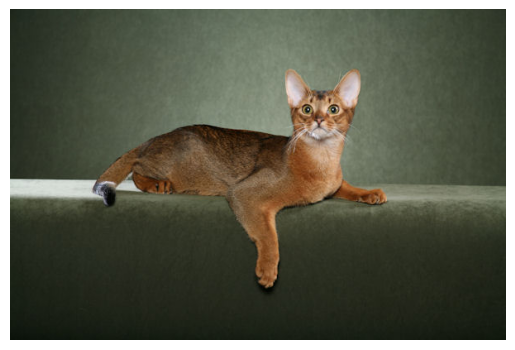

In [19]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

predict_image("/content/pet_dataset/images/Abyssinian_1.jpg")

# 19. Confusion Matrix

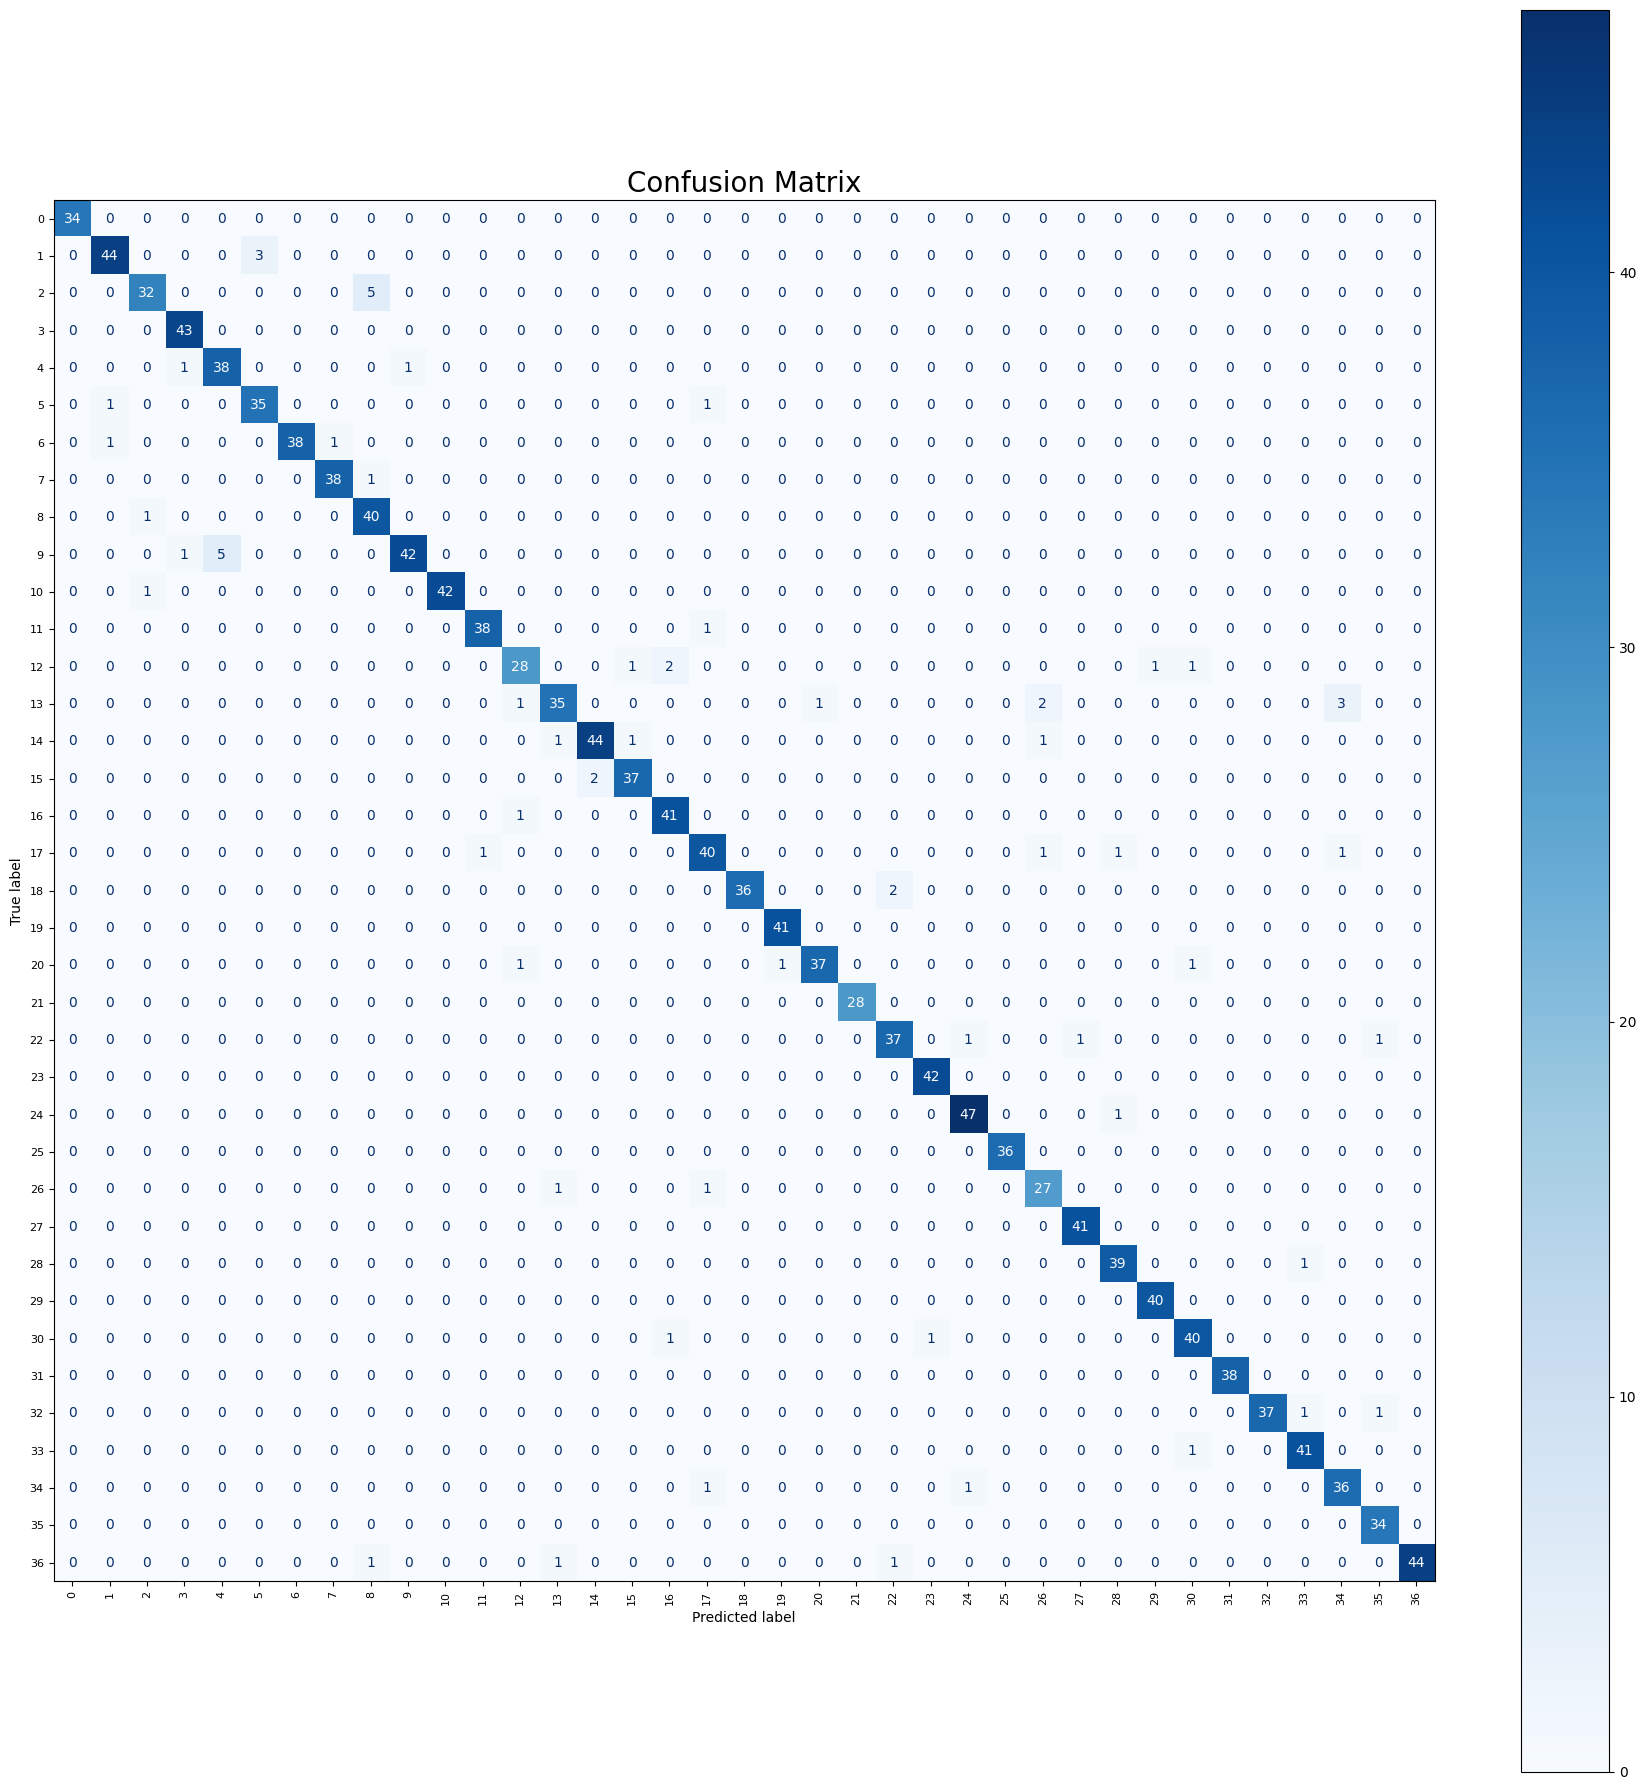

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(model, loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    fig, ax = plt.subplots(figsize=(18, 18))

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues', ax=ax, colorbar=True)

    ax.set_title("Confusion Matrix", fontsize=20)
    ax.tick_params(axis='x', labelsize=8, rotation=90)
    ax.tick_params(axis='y', labelsize=8)

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(model, val_loader)

# 20. Per-Class Accuracy

In [25]:
def per_class_accuracy(model, loader):
    model.eval()

    class_correct = np.zeros(len(class_to_idx))
    class_total = np.zeros(len(class_to_idx))

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            for i in range(len(labels)):
                label = labels[i].item()
                pred = preds[i].item()

                if label == pred:
                    class_correct[label] += 1

                class_total[label] += 1

    idx_to_class = {v: k for k, v in class_to_idx.items()}

    results = []

    for i in range(len(class_to_idx)):
        acc = 100 * class_correct[i] / class_total[i]
        results.append((idx_to_class[i], acc))

    results.sort(key=lambda x: x[1])

    print("\nPer-class Accuracy (Worst → Best):\n")
    for cls, acc in results:
        print(f"{cls:<25} : {acc:.2f}%")
per_class_accuracy(model, val_loader)


Per-class Accuracy (Worst → Best):

american_pit_bull_terrier : 83.33%
american_bulldog          : 84.85%
Birman                    : 86.49%
Russian_Blue              : 87.50%
chihuahua                 : 90.91%
german_shorthaired        : 92.50%
havanese                  : 92.50%
miniature_pinscher        : 93.10%
Bengal                    : 93.62%
basset_hound              : 93.62%
yorkshire_terrier         : 93.62%
Egyptian_Mau              : 94.59%
english_cocker_spaniel    : 94.74%
staffordshire_bull_terrier : 94.74%
beagle                    : 94.87%
scottish_terrier          : 94.87%
British_Shorthair         : 95.00%
Maine_Coon                : 95.00%
saint_bernard             : 95.24%
Persian                   : 97.44%
Sphynx                    : 97.44%
pomeranian                : 97.50%
Ragdoll                   : 97.56%
boxer                     : 97.62%
shiba_inu                 : 97.62%
Siamese                   : 97.67%
keeshond                  : 97.92%
Abyssinian       

# 21. Segmentation Setup

In [30]:
!pip install segmentation_models_pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.9 MB/s eta 0:00:00


In [31]:
import os, gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

images_path  = "/content/pet_dataset/images"
masks_path   = "/content/pet_dataset/annotations/trimaps"

Device: cuda


# 22. Segmentation Dataset

In [32]:
class PetSegDataset(Dataset):
    def __init__(self, images_path, masks_path, image_files, transform=None):
        self.images_path = images_path
        self.masks_path  = masks_path
        self.image_files = image_files
        self.transform   = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name  = self.image_files[idx]
        img_path  = os.path.join(self.images_path, img_name)
        mask_path = os.path.join(self.masks_path, img_name.replace(".jpg", ".png"))

        image = np.array(Image.open(img_path).convert("RGB"))
        mask  = np.array(Image.open(mask_path))

        # Trimap: 1=pet, 2=background, 3=uncertain → binary: pet=1, rest=0
        mask = (mask == 1).astype(np.float32)

        if self.transform:
            aug   = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask  = aug["mask"].unsqueeze(0)

        return image, mask

# 23. Segmentation Transforms

In [33]:
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.88, 1.12), translate_percent=0.06,
             rotate=(-20, 20), shear=(-5, 5), p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.05, p=0.4),
    A.OneOf([
        A.GaussNoise(p=1),
        A.GaussianBlur(p=1),
    ], p=0.2),
    A.GridDistortion(p=0.2),           # helps with edge accuracy
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

# 24. Segmentation DataLoaders

In [34]:
all_files = sorted([f for f in os.listdir(images_path) if f.endswith(".jpg")])
train_files, val_files = train_test_split(all_files, test_size=0.2,
                                          random_state=42, shuffle=True)

train_dataset = PetSegDataset(images_path, masks_path, train_files, train_transform)
val_dataset   = PetSegDataset(images_path, masks_path, val_files,   val_transform)

# batch=8 keeps GPU memory comfortable on T4 with UNet++
train_loader = DataLoader(train_dataset, batch_size=16,  shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=16,  shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Train: 5912 | Val: 1478


# 25. Segmentation Model (UNet++)

In [35]:
# UnetPlusPlus has better skip-connection aggregation than plain Unet
# EfficientNet-B2 is stronger than ResNet34 but still light on T4
model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b2",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None,
    decoder_attention_type="scse",   # squeeze-and-excitation on decoder blocks
).to(device)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model params: {total_params:.1f}M")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Model params: 10.5M


# 26. Segmentation Loss Function

In [36]:
# Tversky with alpha>0.5 penalises false negatives more → better boundary recall
tversky_loss = smp.losses.TverskyLoss(mode='binary', alpha=0.3, beta=0.7)
focal_loss   = smp.losses.FocalLoss(mode='binary', gamma=2.0)

def combined_loss(preds, targets):
    return 0.6 * tversky_loss(preds, targets) + 0.4 * focal_loss(preds, targets)

# 27. Optimizer & Scheduler

In [37]:
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

# 3-epoch linear warmup then cosine decay
warmup   = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)
cosine   = CosineAnnealingLR(optimizer, T_max=12, eta_min=1e-6)
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[3])

# 28. Segmentation Training Loop

In [38]:
from torch.amp import autocast, GradScaler
import torch
import gc
from tqdm import tqdm
import segmentation_models_pytorch as smp

scaler    = GradScaler()
best_iou  = 0.0
best_state = None
num_epochs = 15
patience   = 4
patience_counter = 0

for epoch in range(1, num_epochs + 1):
    # ── train ──────────────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{num_epochs}"):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()

        with autocast(device_type="cuda"):
            outputs = model(images)
            loss    = combined_loss(outputs, masks)

        scaler.scale(loss).backward()

        # gradient clipping — stabilizes training
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    scheduler.step()

    # ── validate ────────────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    tp_s = fp_s = fn_s = tn_s = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            with autocast(device_type="cuda"):
                outputs = model(images)
                val_loss += combined_loss(outputs, masks).item()

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).long()

            tp, fp, fn, tn = smp.metrics.get_stats(preds, masks.long(), mode="binary")
            tp_s += tp.sum(); fp_s += fp.sum()
            fn_s += fn.sum(); tn_s += tn.sum()

    iou  = smp.metrics.iou_score(tp_s, fp_s, fn_s, tn_s, reduction="micro").item()
    dice = smp.metrics.f1_score(tp_s,  fp_s, fn_s, tn_s, reduction="micro").item()
    acc  = smp.metrics.accuracy(tp_s,  fp_s, fn_s, tn_s, reduction="micro").item()
    prec = smp.metrics.precision(tp_s, fp_s, fn_s, tn_s, reduction="micro").item()
    rec  = smp.metrics.recall(tp_s,    fp_s, fn_s, tn_s, reduction="micro").item()

    flag = ""
    if iou > best_iou:
        best_iou   = iou
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        torch.save(model.state_dict(), "best_seg_model.pth")

        patience_counter = 0
        flag = "  ← best"
    else:
        patience_counter += 1

    print(f"Ep {epoch:02d} | "
          f"TrLoss {train_loss/len(train_loader):.4f} | "
          f"VaLoss {val_loss/len(val_loader):.4f} | "
          f"IoU {iou:.4f} | Dice {dice:.4f} | "
          f"Prec {prec:.4f} | Rec {rec:.4f} | Acc {acc:.4f}"
          f"{flag}")

    # free GPU memory (important for Colab)
    torch.cuda.empty_cache()
    gc.collect()

    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# restore best weights into model
model.load_state_dict(best_state)
print(f"\nRestored best model (IoU: {best_iou:.4f})")

Epoch 01/15: 100%|██████████| 370/370 [07:02<00:00,  1.14s/it]


Ep 01 | TrLoss 0.2543 | VaLoss 0.1209 | IoU 0.8462 | Dice 0.9167 | Prec 0.8760 | Rec 0.9613 | Acc 0.9479  ← best


Epoch 02/15: 100%|██████████| 370/370 [02:18<00:00,  2.66it/s]


Ep 02 | TrLoss 0.1125 | VaLoss 0.0756 | IoU 0.8722 | Dice 0.9317 | Prec 0.8965 | Rec 0.9698 | Acc 0.9576  ← best


Epoch 03/15: 100%|██████████| 370/370 [02:13<00:00,  2.77it/s]


...

Ep 13 | TrLoss 0.0537 | VaLoss 0.0601 | IoU 0.8945 | Dice 0.9443 | Prec 0.9160 | Rec 0.9744 | Acc 0.9657  ← best


Epoch 14/15: 100%|██████████| 370/370 [02:08<00:00,  2.87it/s]


Ep 14 | TrLoss 0.0532 | VaLoss 0.0596 | IoU 0.8957 | Dice 0.9450 | Prec 0.9178 | Rec 0.9739 | Acc 0.9662  ← best


Epoch 15/15: 100%|██████████| 370/370 [02:08<00:00,  2.89it/s]


Ep 15 | TrLoss 0.0519 | VaLoss 0.0599 | IoU 0.8968 | Dice 0.9456 | Prec 0.9199 | Rec 0.9728 | Acc 0.9666  ← best

Restored best model (IoU: 0.8968)


# 29. Final Segmentation Evaluation

In [39]:
from torch.amp import autocast, GradScaler
import torch
import gc
from tqdm import tqdm
import segmentation_models_pytorch as smp

scaler    = GradScaler()
best_iou  = 0.0
best_state = None
num_epochs = 15
patience   = 4
patience_counter = 0

for epoch in range(1, num_epochs + 1):
    # ── train ──────────────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{num_epochs}"):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()

        with autocast(device_type="cuda"):
            outputs = model(images)
            loss    = combined_loss(outputs, masks)

        scaler.scale(loss).backward()

        # gradient clipping — stabilizes training
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    scheduler.step()

    # ── validate ────────────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    tp_s = fp_s = fn_s = tn_s = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            with autocast(device_type="cuda"):
                outputs = model(images)
                val_loss += combined_loss(outputs, masks).item()

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).long()

            tp, fp, fn, tn = smp.metrics.get_stats(preds, masks.long(), mode="binary")
            tp_s += tp.sum(); fp_s += fp.sum()
            fn_s += fn.sum(); tn_s += tn.sum()

    iou  = smp.metrics.iou_score(tp_s, fp_s, fn_s, tn_s, reduction="micro").item()
    dice = smp.metrics.f1_score(tp_s,  fp_s, fn_s, tn_s, reduction="micro").item()
    acc  = smp.metrics.accuracy(tp_s,  fp_s, fn_s, tn_s, reduction="micro").item()
    prec = smp.metrics.precision(tp_s, fp_s, fn_s, tn_s, reduction="micro").item()
    rec  = smp.metrics.recall(tp_s,    fp_s, fn_s, tn_s, reduction="micro").item()

    flag = ""
    if iou > best_iou:
        best_iou   = iou
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        torch.save(model.state_dict(), "best_seg_model.pth")

        patience_counter = 0
        flag = "  ← best"
    else:
        patience_counter += 1

    print(f"Ep {epoch:02d} | "
          f"TrLoss {train_loss/len(train_loader):.4f} | "
          f"VaLoss {val_loss/len(val_loader):.4f} | "
          f"IoU {iou:.4f} | Dice {dice:.4f} | "
          f"Prec {prec:.4f} | Rec {rec:.4f} | Acc {acc:.4f}"
          f"{flag}")

    # free GPU memory (important for Colab)
    torch.cuda.empty_cache()
    gc.collect()

    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# restore best weights into model
model.load_state_dict(best_state)
print(f"\nRestored best model (IoU: {best_iou:.4f})")

Epoch 01/15: 100%|██████████| 370/370 [02:09<00:00,  2.86it/s]


Ep 01 | TrLoss 0.0519 | VaLoss 0.0595 | IoU 0.8966 | Dice 0.9455 | Prec 0.9190 | Rec 0.9735 | Acc 0.9665  ← best


Epoch 02/15: 100%|██████████| 370/370 [02:09<00:00,  2.86it/s]


Ep 02 | TrLoss 0.0524 | VaLoss 0.0602 | IoU 0.8965 | Dice 0.9454 | Prec 0.9191 | Rec 0.9734 | Acc 0.9665


Epoch 03/15: 100%|██████████| 370/370 [02:09<00:00,  2.86it/s]


...

Ep 05 | TrLoss 0.0524 | VaLoss 0.0597 | IoU 0.8961 | Dice 0.9452 | Prec 0.9190 | Rec 0.9729 | Acc 0.9664


Epoch 06/15: 100%|██████████| 370/370 [02:08<00:00,  2.88it/s]


Ep 06 | TrLoss 0.0529 | VaLoss 0.0599 | IoU 0.8957 | Dice 0.9450 | Prec 0.9178 | Rec 0.9739 | Acc 0.9662


Epoch 07/15: 100%|██████████| 370/370 [02:08<00:00,  2.89it/s]


Ep 07 | TrLoss 0.0552 | VaLoss 0.0630 | IoU 0.8935 | Dice 0.9438 | Prec 0.9149 | Rec 0.9745 | Acc 0.9654

Early stopping at epoch 7

Restored best model (IoU: 0.8969)


# 30. Visualization of Predictions

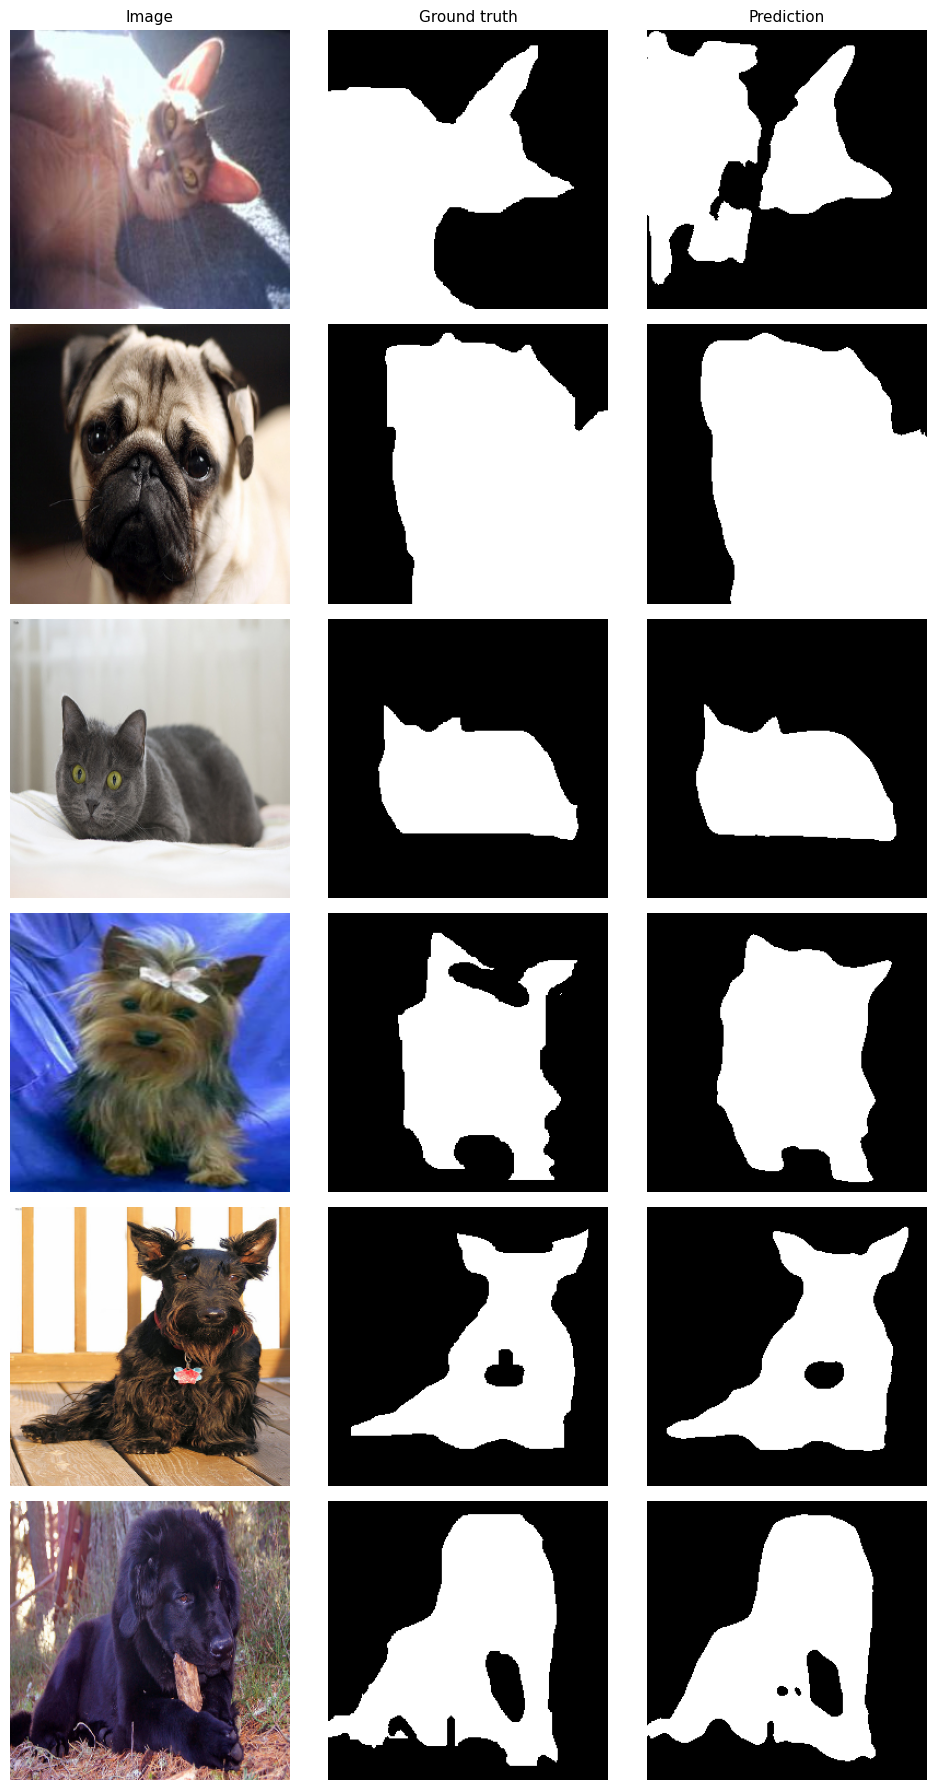

In [40]:
def visualize_predictions(model, dataset, n=6, threshold=0.5):
    model.eval()
    indices = np.random.choice(len(dataset), n, replace=False)
    fig, axes = plt.subplots(n, 3, figsize=(10, n * 3))
    cols = ["Image", "Ground truth", "Prediction"]
    for ax, col in zip(axes[0], cols):
        ax.set_title(col, fontsize=11)

    inv_mean = np.array([0.485, 0.456, 0.406])
    inv_std  = np.array([0.229, 0.224, 0.225])

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_t, mask_t = dataset[idx]
            output = model(img_t.unsqueeze(0).to(device))
            pred   = (torch.sigmoid(output) > threshold).squeeze().cpu().numpy()

            # denormalise image for display
            img_np = img_t.permute(1, 2, 0).numpy()
            img_np = np.clip(img_np * inv_std + inv_mean, 0, 1)
            gt_np  = mask_t.squeeze().numpy()

            axes[row, 0].imshow(img_np)
            axes[row, 1].imshow(gt_np,  cmap="gray")
            axes[row, 2].imshow(pred,   cmap="gray")
            for ax in axes[row]:
                ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(model, val_dataset, n=6)

# 31. Gradio Setup

In [41]:
!pip install gradio -q

In [42]:
import gradio as gr
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image
from torchvision import transforms
import matplotlib.cm as cm

infer_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# 35. Combined Classification and Segmentation Inference Function

In [43]:
def predict(pil_image):
    img_t = infer_transform(pil_image).unsqueeze(0).to(device)

    with torch.no_grad():
        # ── classification ──────────────────────────────────────────────────
        cls_out = cls_model(img_t)
        probs   = F.softmax(cls_out, dim=1).squeeze()
        top5_probs, top5_idxs = torch.topk(probs, 5)

        # FIX: pass raw 0-1 probabilities, not percentages
        # gr.Label multiplies by 100 internally
        top5 = {
            idx_to_class[i.item()].replace("_", " ").title(): round(p.item(), 4)
            for p, i in zip(top5_probs, top5_idxs)
        }

        # ── segmentation ────────────────────────────────────────────────────
        seg_out  = seg_model(img_t)
        seg_prob = torch.sigmoid(seg_out).squeeze().cpu().numpy()
        seg_mask = (seg_prob > 0.5).astype(np.uint8)

    # ── overlay ─────────────────────────────────────────────────────────────
    orig    = np.array(pil_image.resize((256, 256))).astype(np.float32) / 255.0
    overlay = orig.copy()
    overlay[seg_mask == 1] = overlay[seg_mask == 1] * 0.5 + np.array([0, 0.8, 0.2]) * 0.5
    overlay[seg_mask == 0] = overlay[seg_mask == 0] * 0.6
    overlay = (np.clip(overlay, 0, 1) * 255).astype(np.uint8)

    # ── heatmap ──────────────────────────────────────────────────────────────
    heatmap = cm.RdYlGn(seg_prob)[:, :, :3]
    heatmap = (heatmap * 255).astype(np.uint8)

    return top5, Image.fromarray(overlay), Image.fromarray(heatmap)

# 36. Load Trained Classification Model for Inference

In [44]:
import torchvision.models as models

# ── classifier (same as before, this worked) ──────────────────────────────────
cls_model = models.efficientnet_b0(weights=None)
num_features = cls_model.classifier[1].in_features
cls_model.classifier = nn.Sequential(
    nn.BatchNorm1d(num_features),
    nn.Dropout(0.5),
    nn.Linear(num_features, len(class_to_idx))
)
cls_model.load_state_dict(torch.load("best_model.pth", map_location=device))
cls_model = cls_model.to(device)
cls_model.eval()
print("Classifier loaded")

Classifier loaded


# 37. Load Trained Segmentation Model for Inference

In [50]:
seg_model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b2",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None,
    decoder_attention_type="scse",
)

seg_model.load_state_dict(torch.load("best_seg_model.pth", map_location=device))

seg_model = seg_model.to(device)
seg_model.eval()

print("Segmentation model loaded")

Segmentation model loaded


# 38. Gradio Interface Setup for Inference

In [51]:
with gr.Blocks(title="Pet Breed Classifier + Segmentation") as demo:

    gr.Markdown("## Pet Breed Classifier + Segmentation")
    gr.Markdown("Upload a photo of a cat or dog — get the breed prediction and a segmentation mask.")

    with gr.Row():
        inp = gr.Image(type="pil", label="Upload pet photo")

    with gr.Row():
        out_overlay  = gr.Image(label="Segmentation overlay")

# 39. Build Gradio Interface

In [55]:
with gr.Blocks(title="Pet Breed Classifier + Segmentation") as demo:

    gr.Markdown("## 🐶🐱 Pet Breed Classifier + Segmentation")
    gr.Markdown("Upload a pet image to get breed prediction + segmentation mask")

    with gr.Row():
        inp = gr.Image(type="pil", label="Upload pet photo")

    with gr.Row():
        out_label   = gr.Label(num_top_classes=5, label="Top Predictions")
        out_overlay = gr.Image(label="Segmentation Overlay")
        out_heatmap = gr.Image(label="Confidence Heatmap")

    btn = gr.Button("Predict")

    btn.click(
        fn=predict,
        inputs=inp,
        outputs=[out_label, out_overlay, out_heatmap]
    )

# 40. Launch Gradio App

In [ ]:
demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fb6667920a3d64b912.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 416, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1160, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error